# Adjoint Optimization of Mirror Shape for Flying Focus Acceleration

Goal is to set up an optimization algorithm to achieve a target pulse shape on axis from a radiation beam reflected from a mirror.

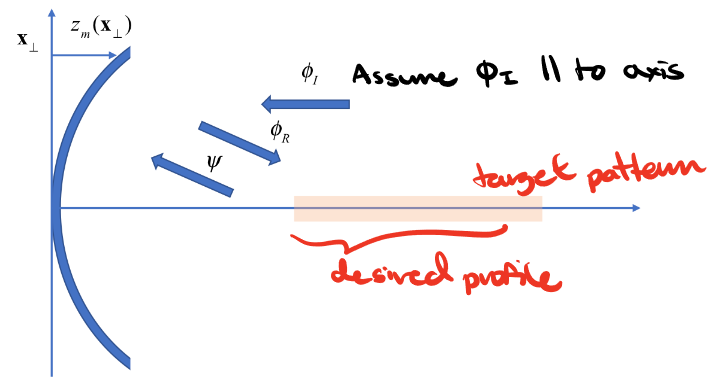

Surface of the mirror is defined by $z=z_m(x_{\perp})$. This is the function we want to optimize

Side note: Sagitta function of optic is defined as: $z(x_{\perp})=\frac{x_{\perp}^2}{R+\sqrt{R^2-(K+1)x_{\perp}^2}}$ where $R$ is the radius of curvature and $K$ is the conic constant

The incident wave $\phi_I$ (assume parallel to axis) comes from the right strikes the mirror and become a reflected wave, $\phi_R$. The reflected wave crosses the z-axis and creates a traveling pulse in the shaded region. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv,jn_zeros,expi
from scipy.optimize import curve_fit
from scipy.integrate import trapezoid,simpson,romb
from numpy.fft import *
import math
from gaussian_beam import *
import time
font = {'size'   : 26}

plt.rc('font', **font)
plt.rcParams['figure.figsize'] = (16,9)
plt.rcParams["lines.linewidth"] = 4


In [2]:
def create_starting_optic(r,R,k=-1):
    z=r*r/(R+np.sqrt(R*R-(k+1)*r*r))
    return z

This function defines the r and k array for a Hankel Transform:

* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function


In [3]:
def DHTarrays(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    r=R*Zeroes[:N]/Zeroes[N-1]
    k=Zeroes[:N]/R
    return np.array([r,k])

This function defines the Transform Matrix for the Hankel Transform
* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function
* `T_R2K` transforms from r space to k space
* `T_K2R` transforms from k space to r space


In [4]:
def DHTtransformMatrix(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    alpha=Zeroes[:N]
    kR = alpha[N-1]
    kmax = kR/R;
    T = jv(ell,np.outer(alpha,alpha)/kR) / np.outer( abs(jv(ell+1,alpha)),abs(jv(ell+1,alpha)) ) / kR;
    #print(T)
    A = abs(jv(ell+1,alpha));
    T_R2K = 4.0*np.pi*(R/kmax)*T * A[:, None] / A[None,:] 
    T_K2R = (1/np.pi)*(kmax/R)*T * A[:, None] / A[None,:] 

    return T_R2K,T_K2R

In [5]:
def mirror(phiI,k0,zm):
    return phiI*np.exp(-2j*k0*zm)

In [6]:
def propagate(fe, k, k0, z, T_R2K, T_K2R):
    # 1) fe is the initial electric field
    # 2) Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ fe
    # Hankel Transform
    # 3) Propagate 𝐸̃ from 𝑧 = 0 to 𝑧 = Δ𝑧 through multiplying 𝐸̃ by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # print(FT.shape)
    # print(T_K2R.shape)
    # 4) Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)
    # fT = (T_K2R@(FT.T)).T
    # print(np.shape(fT))
    return fT

In [7]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, zF, zm, wavelength=1e-6):
    k0 = 2 * np.pi / wavelength
    #     fT_i=prop(phi_I,k,k0,zI,T_R2K,T_K2R)
    phi_R0 = mirror(phi_I, k0, zm)

    fT_f = propagate(phi_R0, k, k0, zF, T_R2K, T_K2R)

    return fT_f

In [8]:
def difference(obs,exp):
    diff=np.abs(np.sum(np.abs(obs)**2)-np.sum(np.abs(exp)**2))/np.abs(np.sum(exp)**2)
    return diff

In [9]:
def retrieve_bounds(z,zi,zf):
    i=len(z[z-zi<0])
    f=len(z[z-zf<=0])
    return i,f

In [10]:
def w_xp(r,R):
#     return np.exp(-r**2/R**2)
    delta=np.zeros(len(r))
    delta[0]=1
    return delta

In [11]:
def w_z(z,zi,zf):
    i,f=retrieve_bounds(z,zi,zf)
    w=np.zeros(len(z))
    w[i:f]=1
    return w

In [12]:
def integrate(r,z,phi1,phi2,method=simpson):
    return np.abs(2*np.pi*method(method(phi1*np.conj(phi2)*r[:,np.newaxis],z),r))

In [13]:
def weighted_phi(r,R,z,zi,zf,phi_r,phi_t):
    pr=phi_r*w_z(z,zi,zf)*w_xp(r,R)[:,np.newaxis]
    pt=phi_t*w_z(z,zi,zf)*w_xp(r,R)[:,np.newaxis]
    return pr,pt

In [14]:
def int_pairs(r,z,pr,pt):
    phi_r_sq=integrate(r,z,pr,pr)
    phi_r_phi_t=integrate(r,z,pr,pt)
    phi_t_sq=integrate(r,z,pt,pt)
    return phi_r_sq,phi_r_phi_t,phi_t_sq

In [15]:
def FOM(prsq,prpt,ptsq):
    return 0.5*(prsq-prpt**2/ptsq)

In [16]:
def mu(prpt,ptsq):
    return prpt/ptsq

In [17]:
def S(pr,pt,prpt,ptsq):
    m=mu(prpt,ptsq)
    s=pr-m*pt
    return s

In [18]:
def calc_psi_hat(k,k0,z,s_hat,method=simpson):
    #print('start psi hat')
    coeff=-1j/(2*k0)
    integrand=np.exp(-1j*np.outer(k**2,z)/(2*k0))*s_hat
    #print('end psi hat')
    return coeff*method(integrand,z)

In [19]:
def adjoint(r,wR,k,k0,z,zmin,zmax,phi_r,phi_t,T_R2K,T_K2R):
    #print('pr pt')
    pR,pT=weighted_phi(r,wR,z,zmin,zmax,phi_r,phi_t)
    #print('int pairs')
    prsq,prpt,ptsq=int_pairs(r,z,pR,pT)
    #print('s')
    s=S(pR,pT,prpt,ptsq)
    s_hat=T_R2K@s
    psi_hat=calc_psi_hat(k,k0,z,s_hat)
    return psi_hat

In [20]:
def gradient(k0,phi_i,psi,z_m):
    return 4*k0**2*phi_i*psi*np.exp(-2j*k0*z_m)

In [21]:
def step(grad,eps,z_m):
    return z_m-eps*grad

In [22]:
def gradients(r,g,filename):
    plt.figure()
    plt.plot(r,np.abs(g),label=r'$|\frac{df}{dz_m}|$')
    plt.plot(r,0.5*(np.real(g)+np.imag(g)),label=r'$\frac{1}{2}(\mathrm{Re}(\frac{df}{dz_m})+\mathrm{Im}({\frac{df}{dz_m}})$')
    plt.xlabel('r (m)')
    #plt.ylabel(r'df/d$z_m$')
    plt.axvline(w0,linestyle='--',c='k', label=r'$w_0$')
    plt.axhline(0,linestyle='--',c='k')
    plt.tight_layout()
    #plt.savefig('delta_dfdz_%d'%nr)
    plt.xlim((0,2*w0))
    plt.legend()
    # plt.show()
    plt.savefig(filename)

In [23]:
def gradient_re_im(r,g,filename):
    plt.plot(r,np.real(g),label=r'$\mathrm{Re}(\frac{df}{dz_m})$')
    plt.plot(r,np.imag(g),label=r'$\mathrm{Im}(\frac{df}{dz_m})$')
    plt.xlabel('r (m)')
    #plt.ylabel(r'df/d$z_m$')
    plt.axvline(w0,linestyle='--',c='k', label=r'$w_0$')
    plt.axhline(0,linestyle='--',c='k')
    plt.tight_layout()
    #plt.savefig('delta_dfdz_%d'%nr)
    plt.xlim((0,2*w0))
    plt.legend()
    # plt.show()
    plt.savefig(filename)

In [24]:
def spikes(mirror):
    dfmr=np.diff(mirror)
    ddfmr=np.diff(dfmr)
    spikes=np.where(ddfmr<-4.5e-7)[0]+1
    return spikes

In [25]:
def shift(mirror,spikes):
    new_mir=np.copy(mirror)
    n=len(spikes) # number of shifts
    spikes=np.append(spikes,len(mirror))
    print(spikes)
    for i in range(n):
        start=spikes[i]
        end=spikes[i+1]
        new_mir[start:end]-=((i+1)*5e-7)
    return new_mir

# Parameters:

All initial parameters are defined here. Default is in kms units

Lens Parameters
* `f` focal length of the lens
* `RoC` radius of curvature of the lens

Beam Parameters
* `wl` wavelength (m)
* `k0` wavenumber
* `w0` spot size (m) $\qquad f_\#=\frac{f}{w_0}$
* `rmax` maximum r value (m)
* `nr` number of points in radial direction
* `zR` rayleigh length

Distance Parameters
* `zi` starting distance away from the mirror
* `zf` final distance after encountering the mirror
* `nzi` number of points in z before the mirror
* `nzf` number of points in z after the mirror
* `zI` defining the z array before the mirror
* `zF` defining the z array after the mirror
* `wR` the diffraction limited spot size

Curve Fit Parameters to retrieve waist at different z locations
* `OoM` order of magnitude of the `w0`^2
* `w_guess` the initial spot size guess that is used to find the spot size 

In [26]:
# Lens parameters
f_targ=0.05625
f_init = 0.05
ell=0
# Beam Parameters
wl=1e-6
k0=2*np.pi/wl
fn=25
w0=f_init/(2*fn)
#w0=0.036
rmax=5*w0
nr=1000
zR=np.pi*w0**2/wl
wR=2/np.pi*fn*wl

# Distance parameters
# zi=0.1*zR
nz=101
dz=0.01
zF=np.linspace(f_targ-dz,f_targ+dz,nz)
nzf=len(zF)
print(nzf)
# Guess parameters
OoM=math.floor(math.log(w0**2, 10))
w_guess=10**OoM
steps=1000
lr=1e-11
fl=len(zF)//2
print(fl)
assert(w0>wR),"Spot size is smaller than diffraction limited spot size"

101
50


In [27]:
[r,k] = DHTarrays(nr,rmax,ell)
[T_R2K,T_K2R] = DHTtransformMatrix(nr,rmax,ell)

phi_I=-np.exp(-(r/w0)**2)


In [28]:
z_res=4*np.pi*k0/(max(k)**2)
print(np.diff(zF)[0])
print(z_res)
assert(np.diff(zF)[0]<z_res),'Need more resolution in z, increase number of points'

0.0001999999999999988
0.00020010003244137593


In [29]:
z_m=create_starting_optic(r,2*f_targ) 
ftf_t = forward_propagation(
    k, phi_I, T_R2K, T_K2R, zF, z_m
)  # Target profile defined using target mirror
z_r=create_starting_optic(r,2*0.05)

# Run through steps

In [30]:
mr=[z_r]
gr=[]
tol=1000
I_oa = []
for i in range(steps):
    if i%50==0: print("STEP %d \t Step Size:%.3e" %(i,tol))
    ftf_r = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, z_r)
    psi_hat=adjoint(r,2*wR,k,k0,zF,f_targ-dz/2,f_targ+dz/2,ftf_r,ftf_t,T_R2K,T_K2R)
    psi=T_K2R@psi_hat
    grad=np.real(gradient(k0,phi_I,psi,z_r))
    z_r=step(grad,lr,z_r)
    mr.append(z_r)
    gr.append(grad)
    I_oa.append(np.abs(ftf_r[0,:])**2)
    tol=np.sum(grad)

STEP 0 	 Step Size:1.000e+03
STEP 50 	 Step Size:5.934e+03
STEP 100 	 Step Size:-2.419e+02
STEP 150 	 Step Size:-1.131e+03
STEP 200 	 Step Size:-4.422e+02
STEP 250 	 Step Size:-2.980e+02
STEP 300 	 Step Size:-2.727e+02
STEP 350 	 Step Size:-2.246e+02
STEP 400 	 Step Size:-1.575e+02
STEP 450 	 Step Size:-1.216e+02
STEP 500 	 Step Size:-9.905e+01
STEP 550 	 Step Size:-8.264e+01
STEP 600 	 Step Size:-6.925e+01
STEP 650 	 Step Size:-5.758e+01
STEP 700 	 Step Size:-4.757e+01
STEP 750 	 Step Size:-3.956e+01
STEP 800 	 Step Size:-3.380e+01
STEP 850 	 Step Size:-3.026e+01
STEP 900 	 Step Size:-2.851e+01
STEP 950 	 Step Size:-2.787e+01


# Total Change in mirror

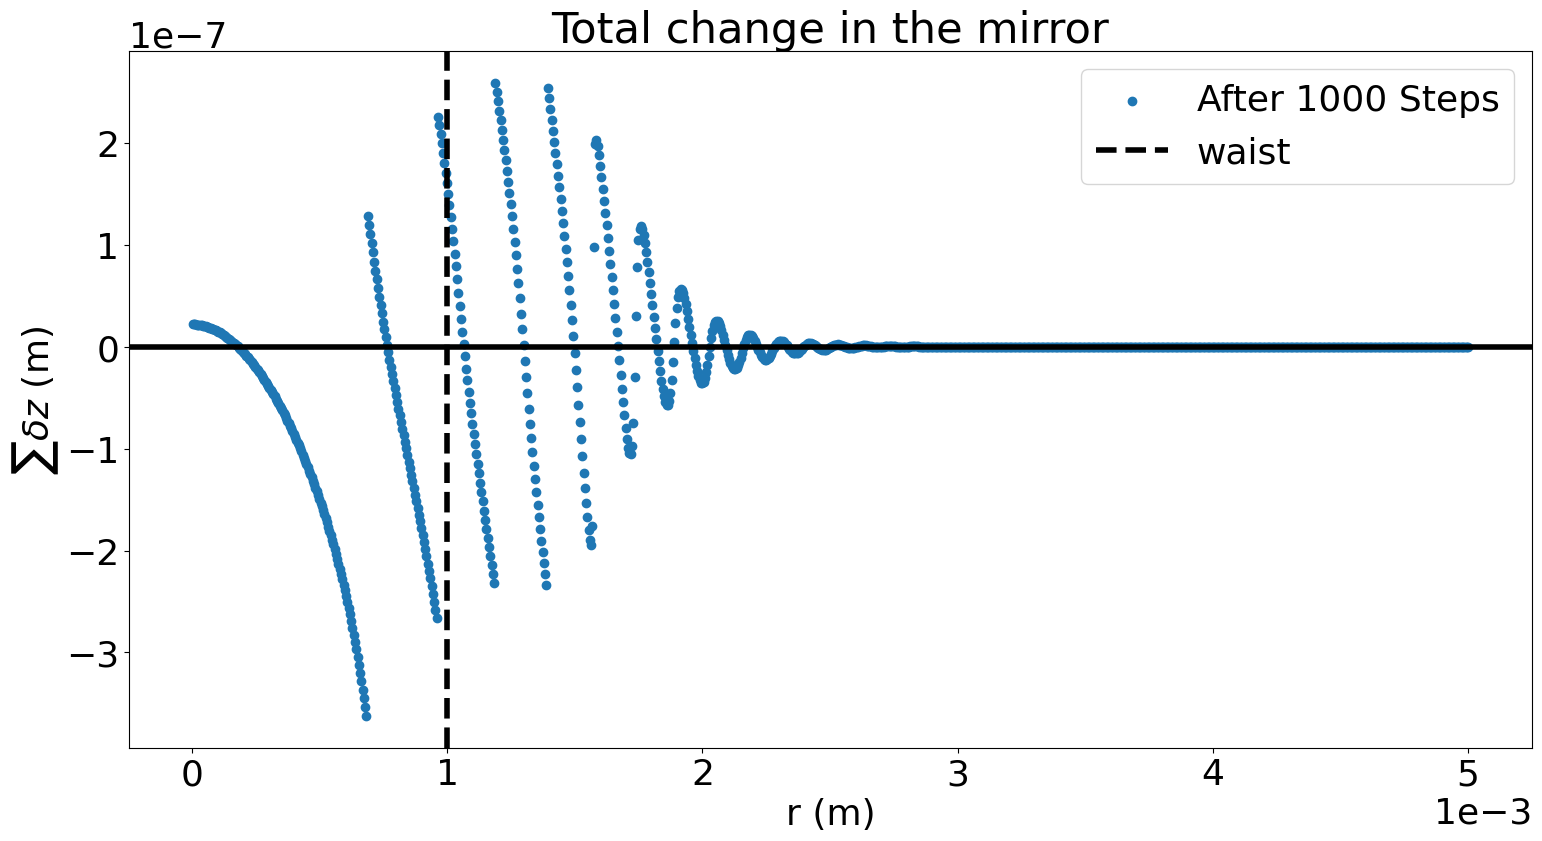

In [31]:
plt.scatter(r,-1*np.sum(gr,axis=0)*lr,label='After 1000 Steps')
# plt.xlim((0,2*w0))
plt.title('Total change in the mirror')
plt.xlabel('r (m)')
plt.ylabel(r'$\sum\delta z$ (m)')
plt.ticklabel_format(axis='both', style='sci', scilimits=(0,0))
plt.axvline(w0,label='waist',linestyle='--',c='k')
plt.axhline(0,c='k')
plt.legend()
plt.tight_layout()
plt.show()
# plt.savefig('delt_scatter_total_change')

# Show Target, Initial, and Final Mirror

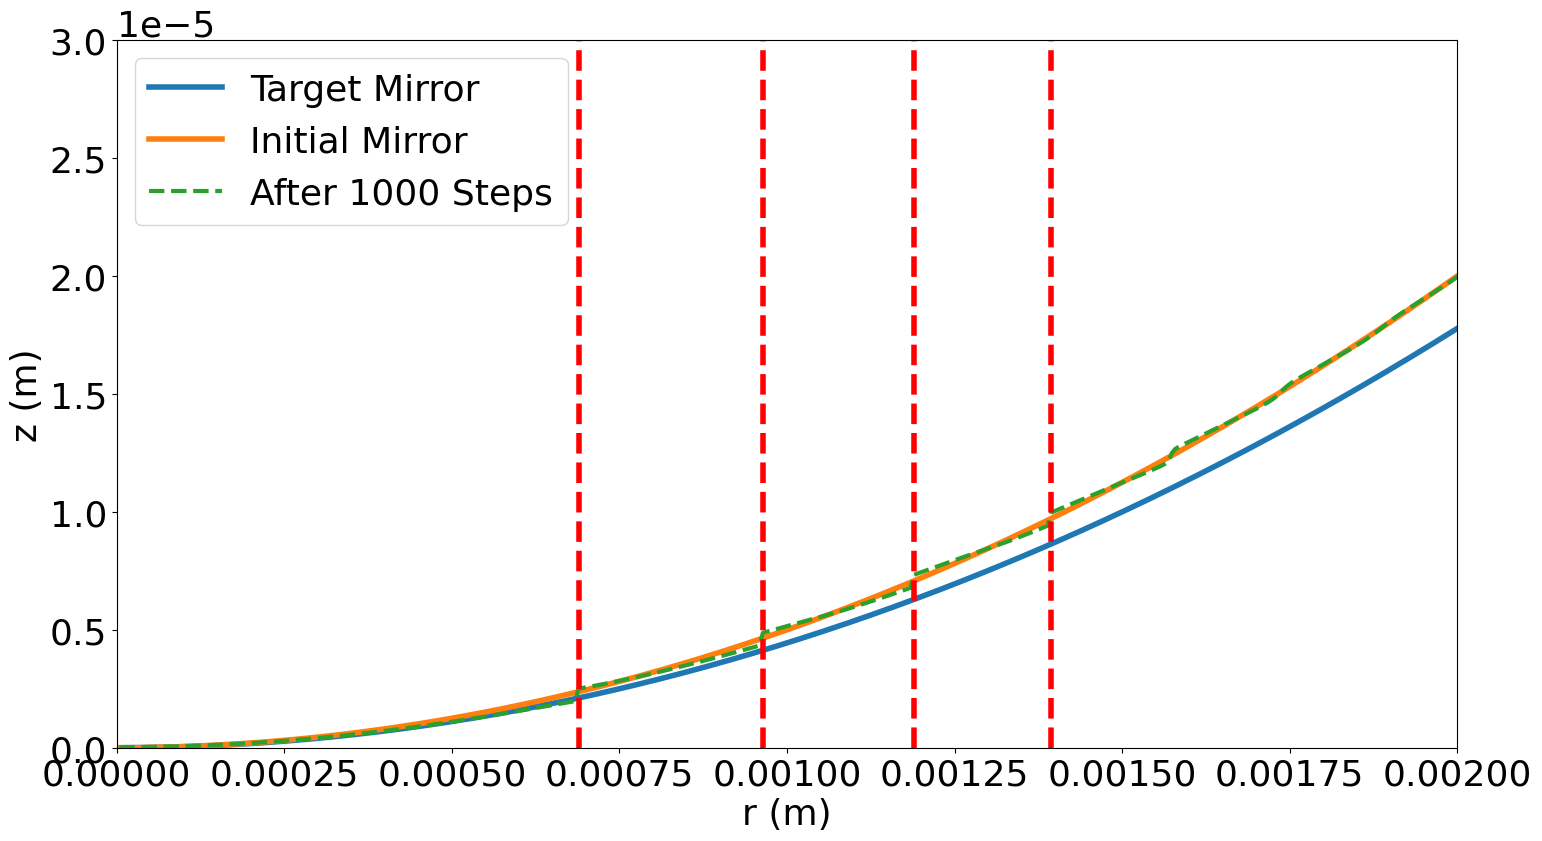

In [32]:
plt.plot(r,z_m,label='Target Mirror')
plt.plot(r,create_starting_optic(r,2*0.05),label='Initial Mirror')
plt.plot(r,mr[-1],label='After %d Steps' % (steps),linestyle='--',linewidth=3)
plt.xlim((0,2*w0))
plt.ylim((0,3e-5))
plt.legend()
plt.xlabel('r (m)')
plt.ylabel('z (m)')

sp=spikes(mr[-1])
for s in r[sp]:
    plt.axvline(s,linestyle='--',c='r')

plt.tight_layout()
plt.show()
# plt.savefig('delta_mirror_1000')

[ 137  192  237  278 1000]


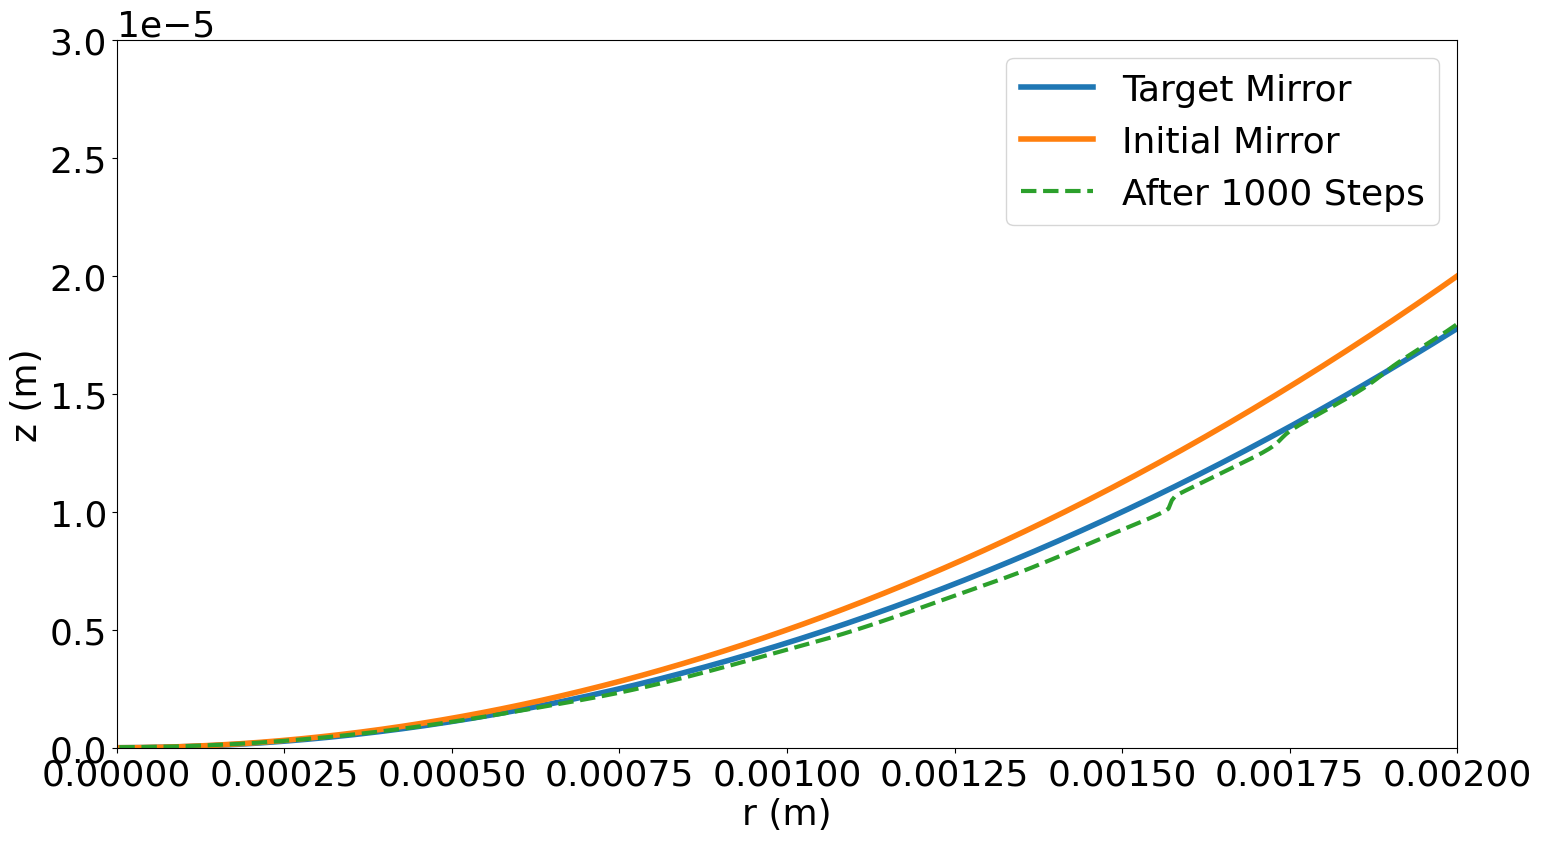

In [33]:
plt.plot(r,z_m,label='Target Mirror')
plt.plot(r,create_starting_optic(r,2*0.05),label='Initial Mirror')

sp=spikes(mr[-1])
smr=shift(mr[-1],sp)

plt.plot(r,smr,label='After %d Steps' % (steps),linestyle='--',linewidth=3)
# me=np.loadtxt('exp_mr.csv')
# plt.plot(r,me,label='exp',linestyle='--',linewidth=3)
plt.xlim((0,2*w0))
plt.ylim((0,3e-5))
plt.legend()
plt.xlabel('r (m)')
plt.ylabel('z (m)')

plt.tight_layout()
plt.show()
# plt.savefig('delta_mirror_1000')

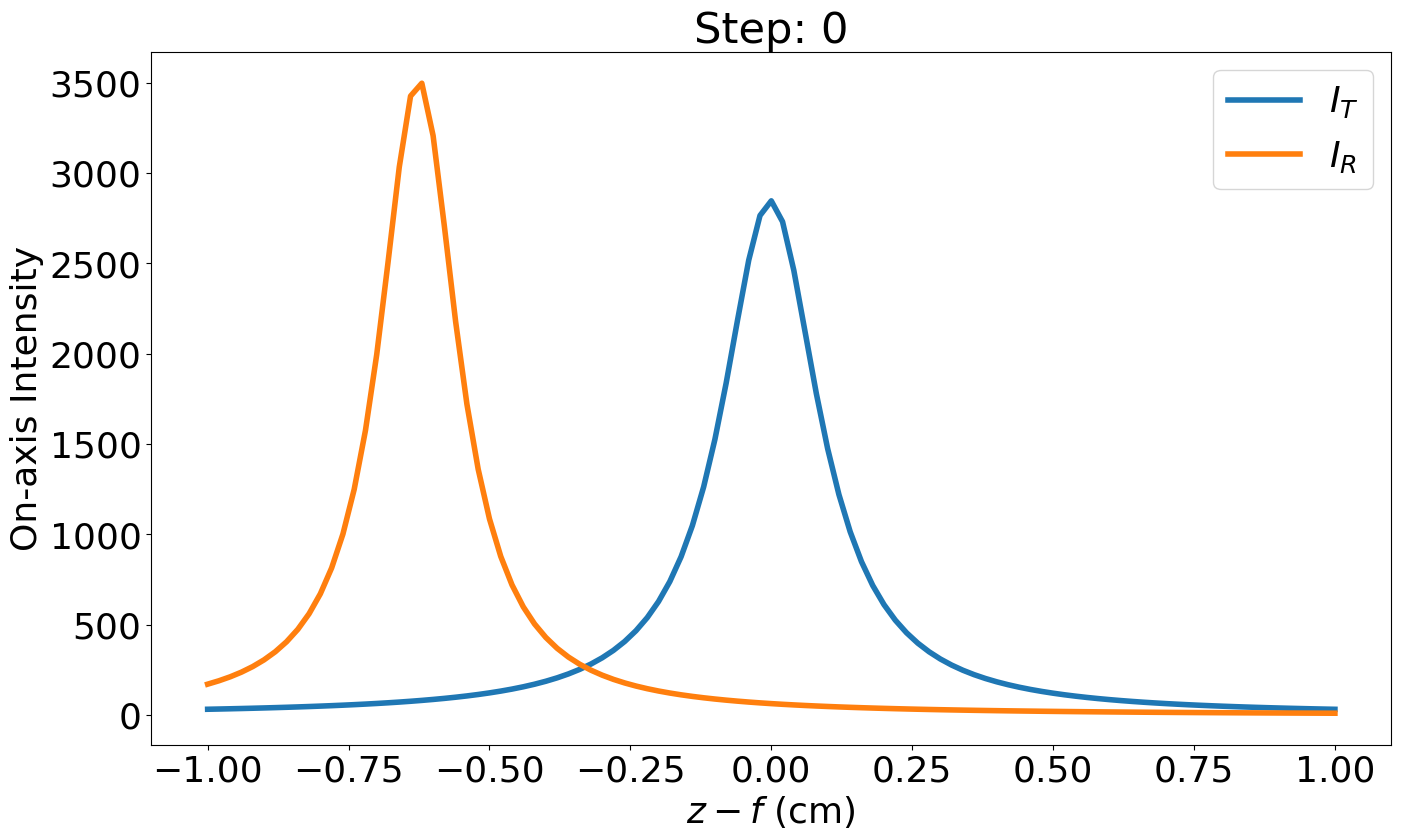

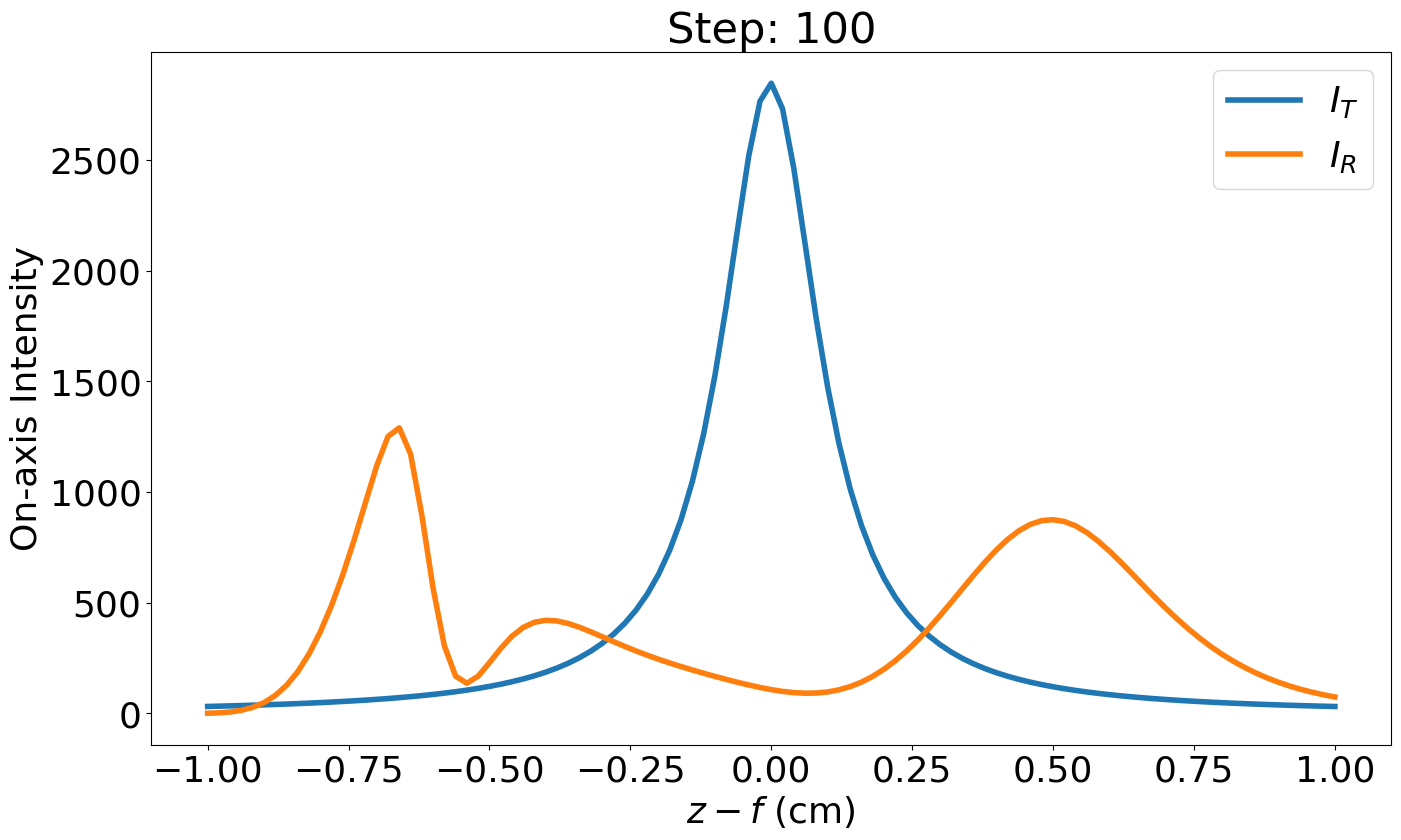

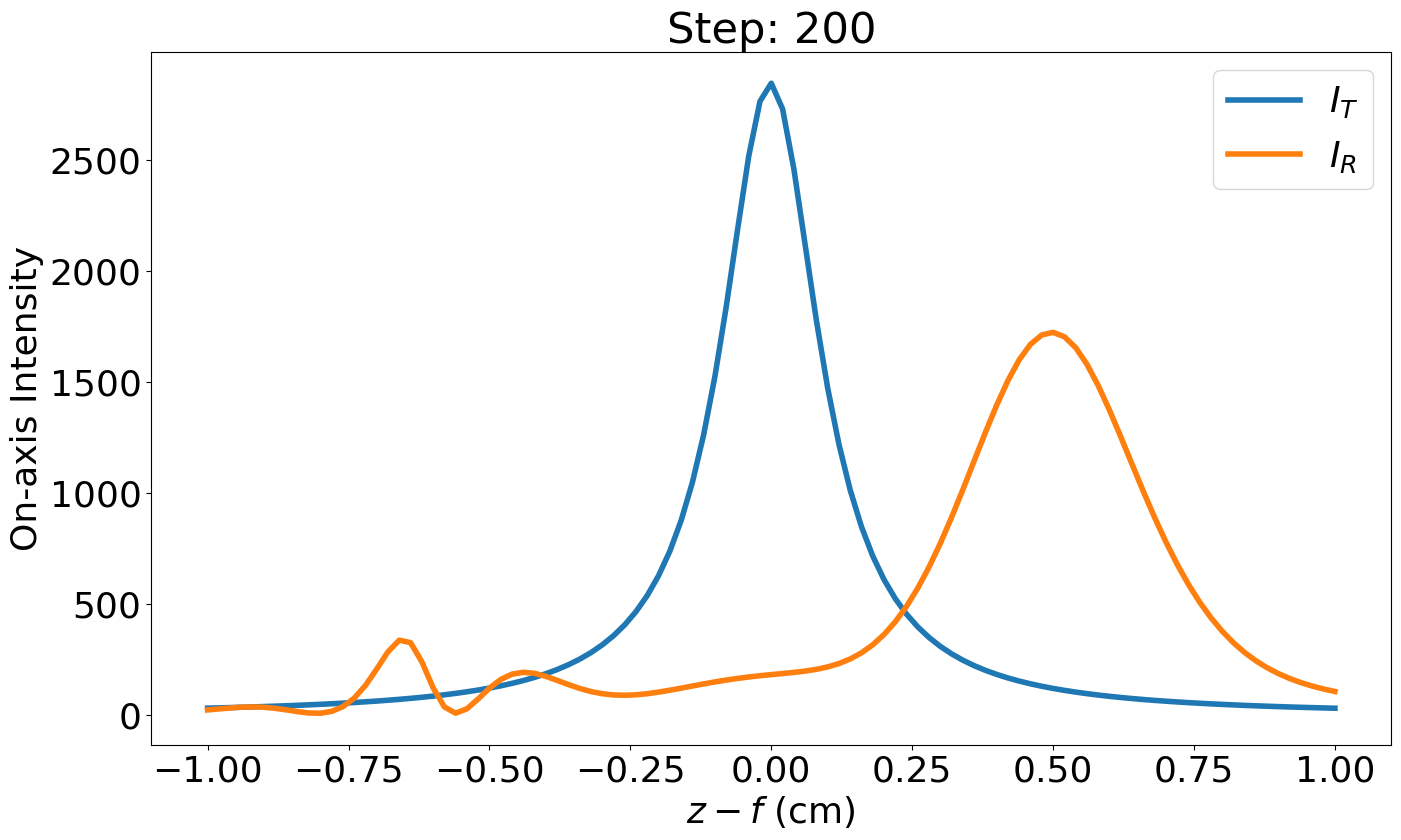

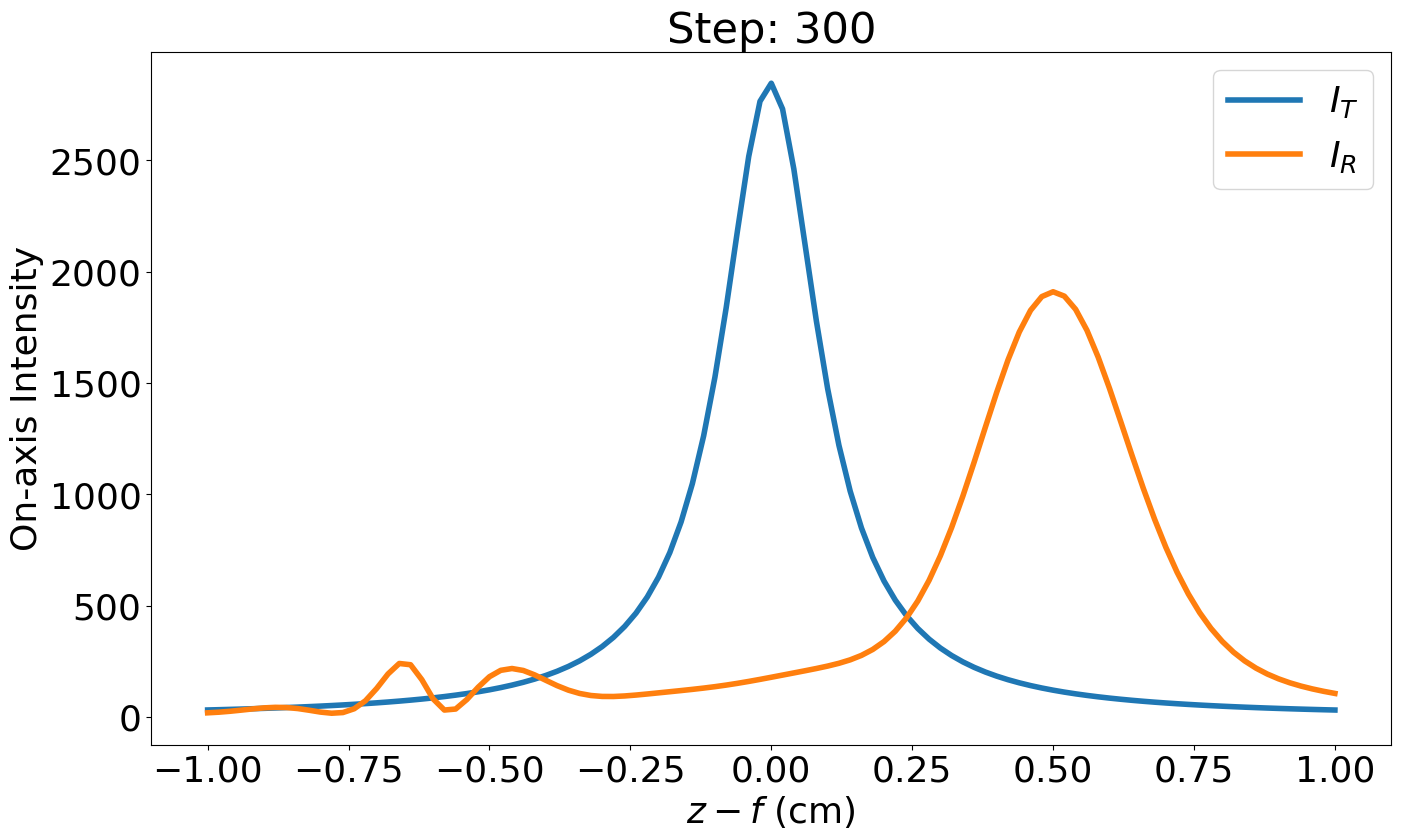

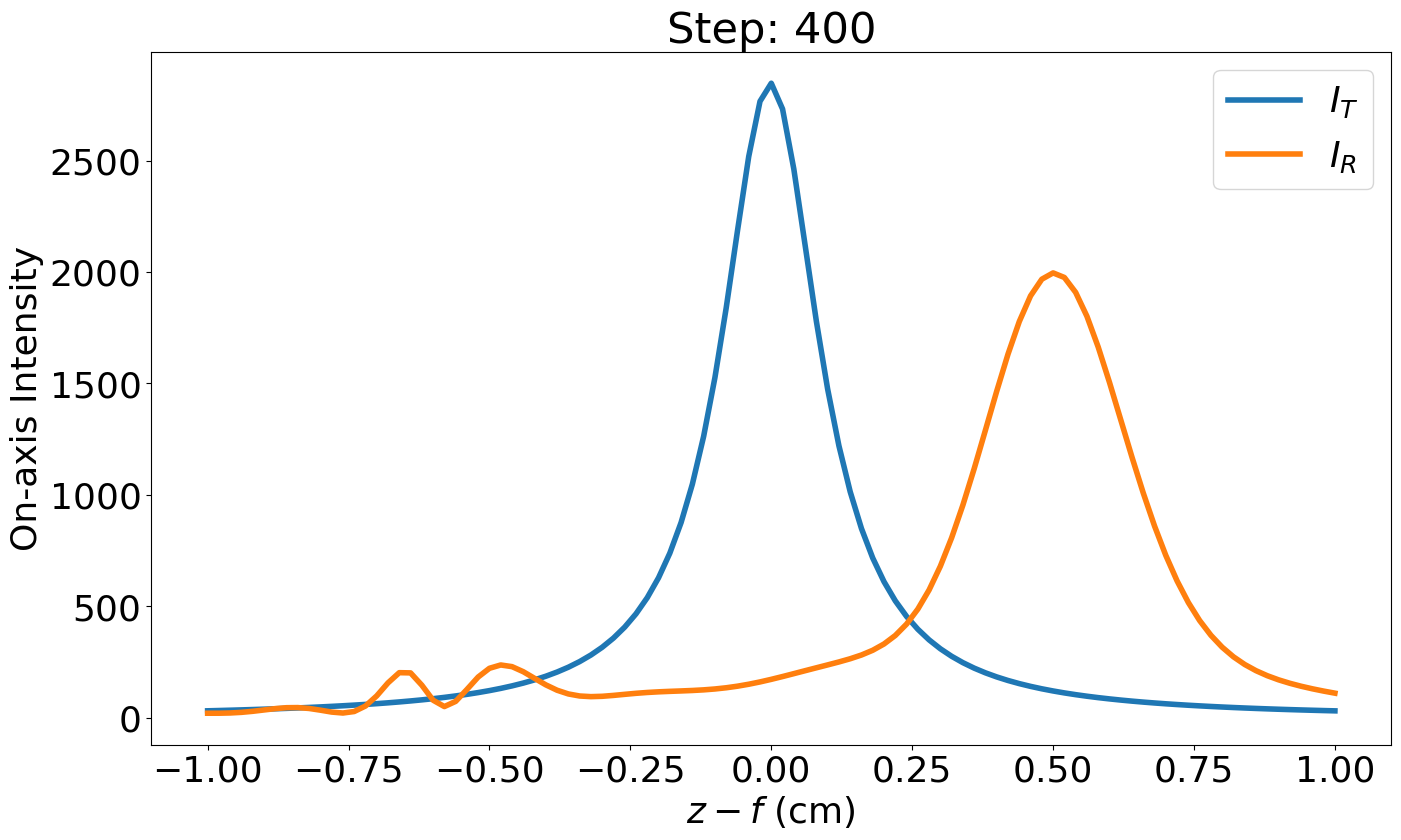

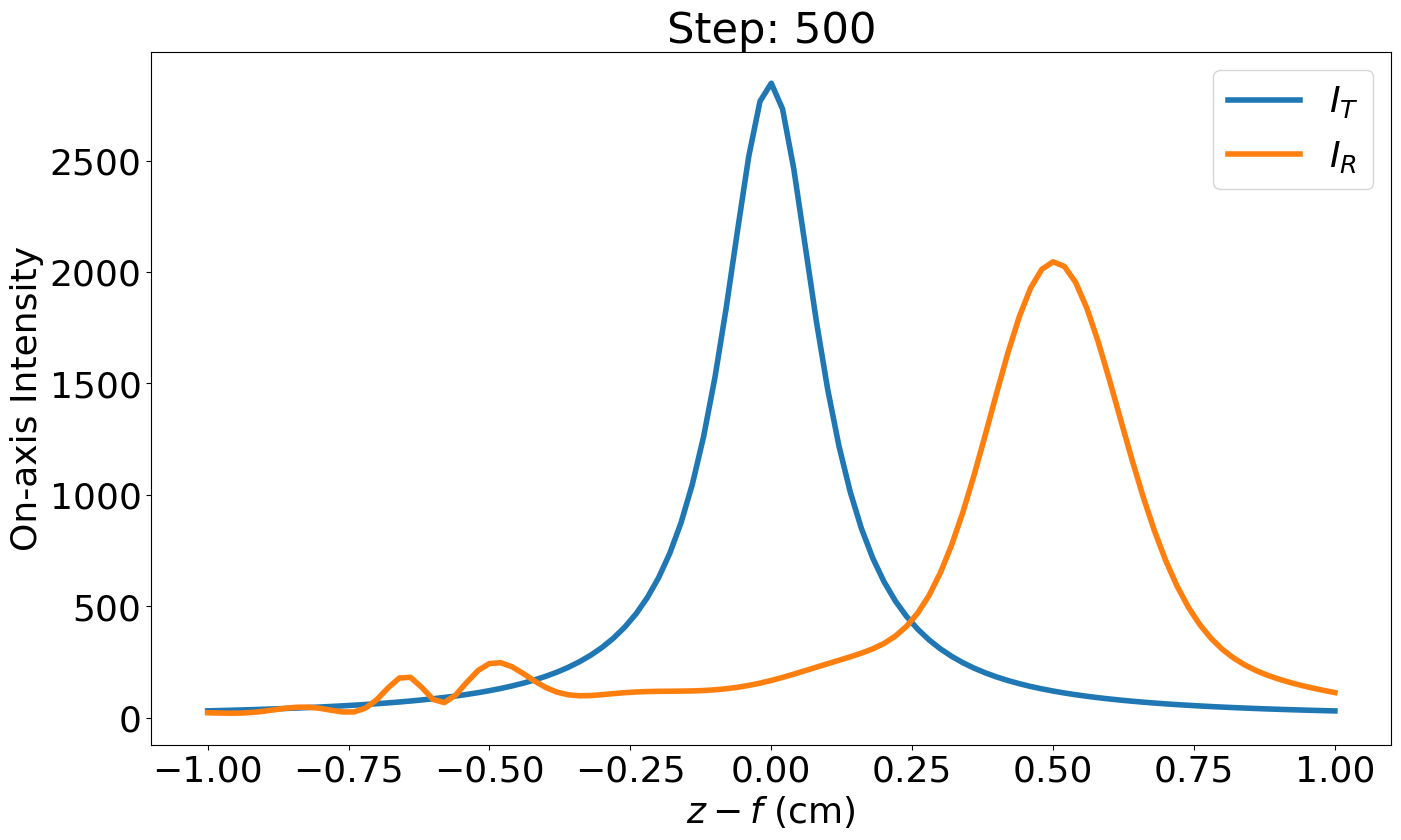

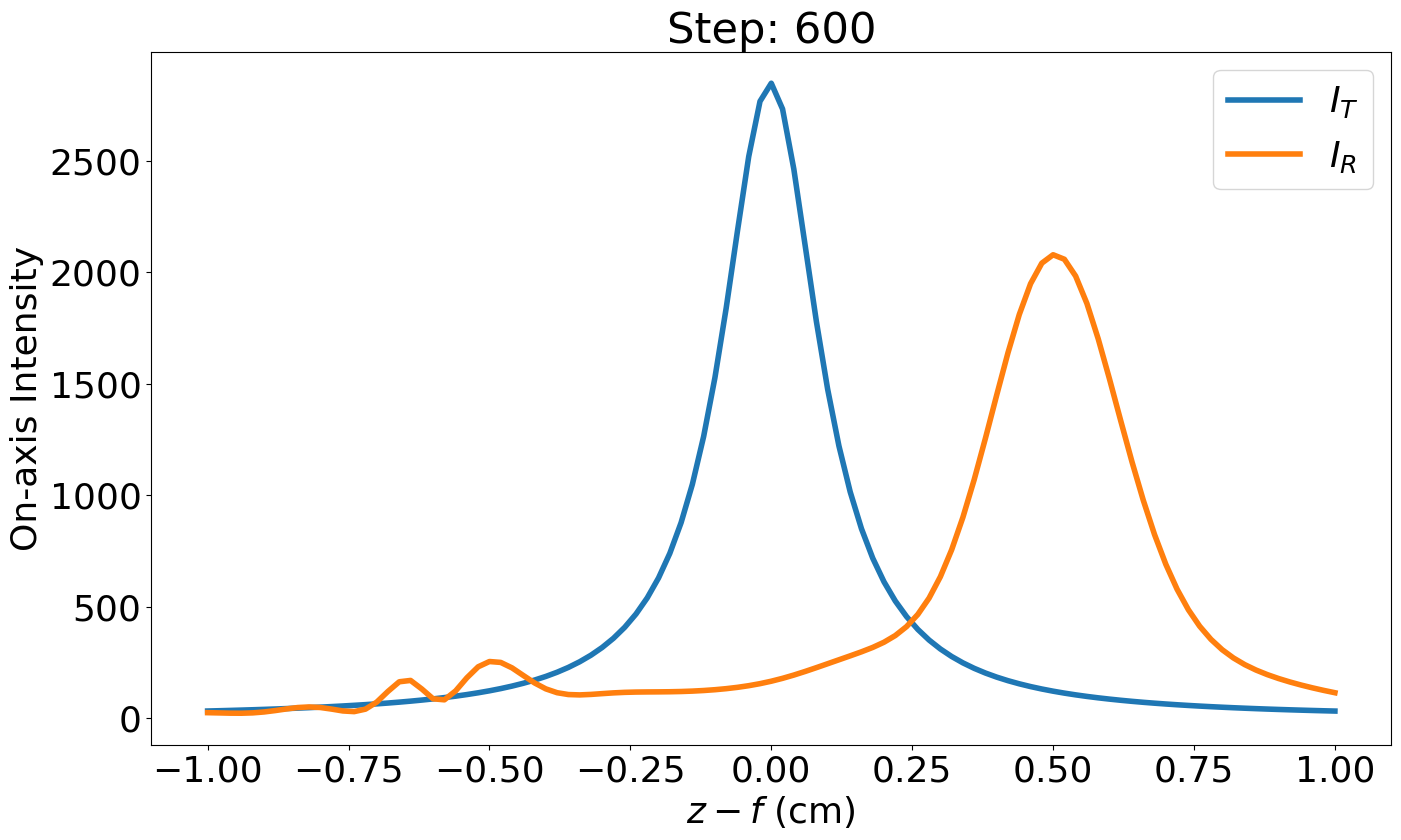

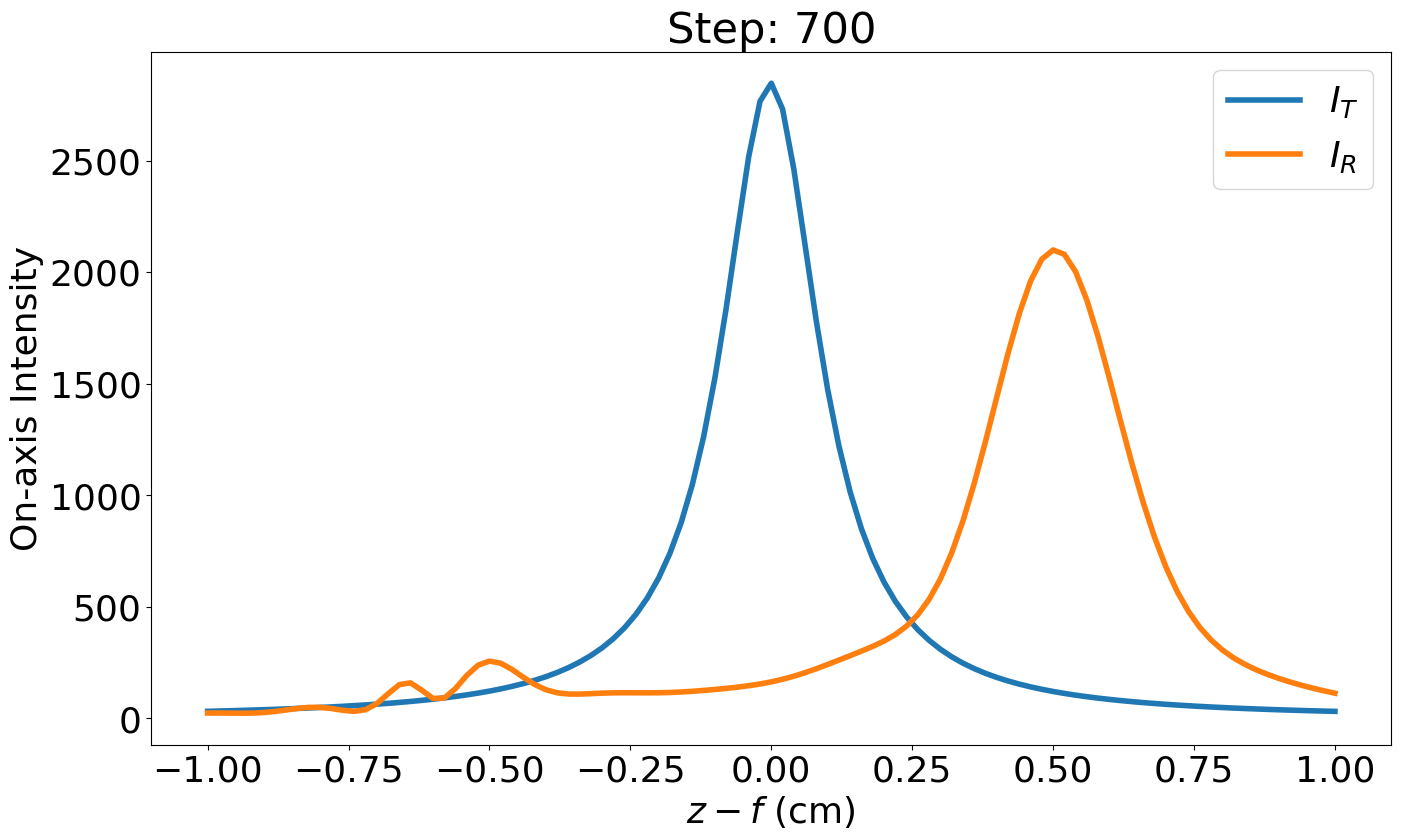

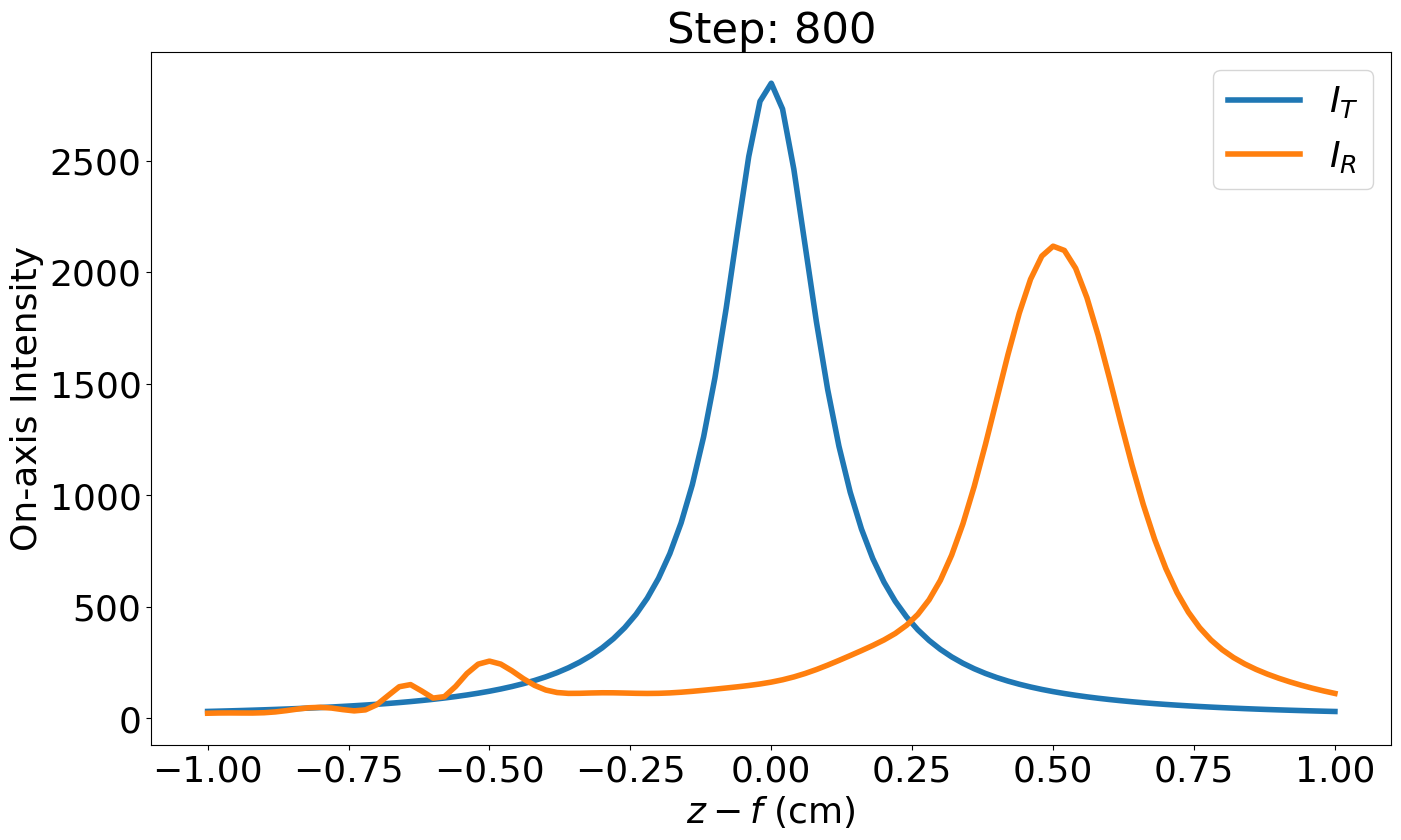

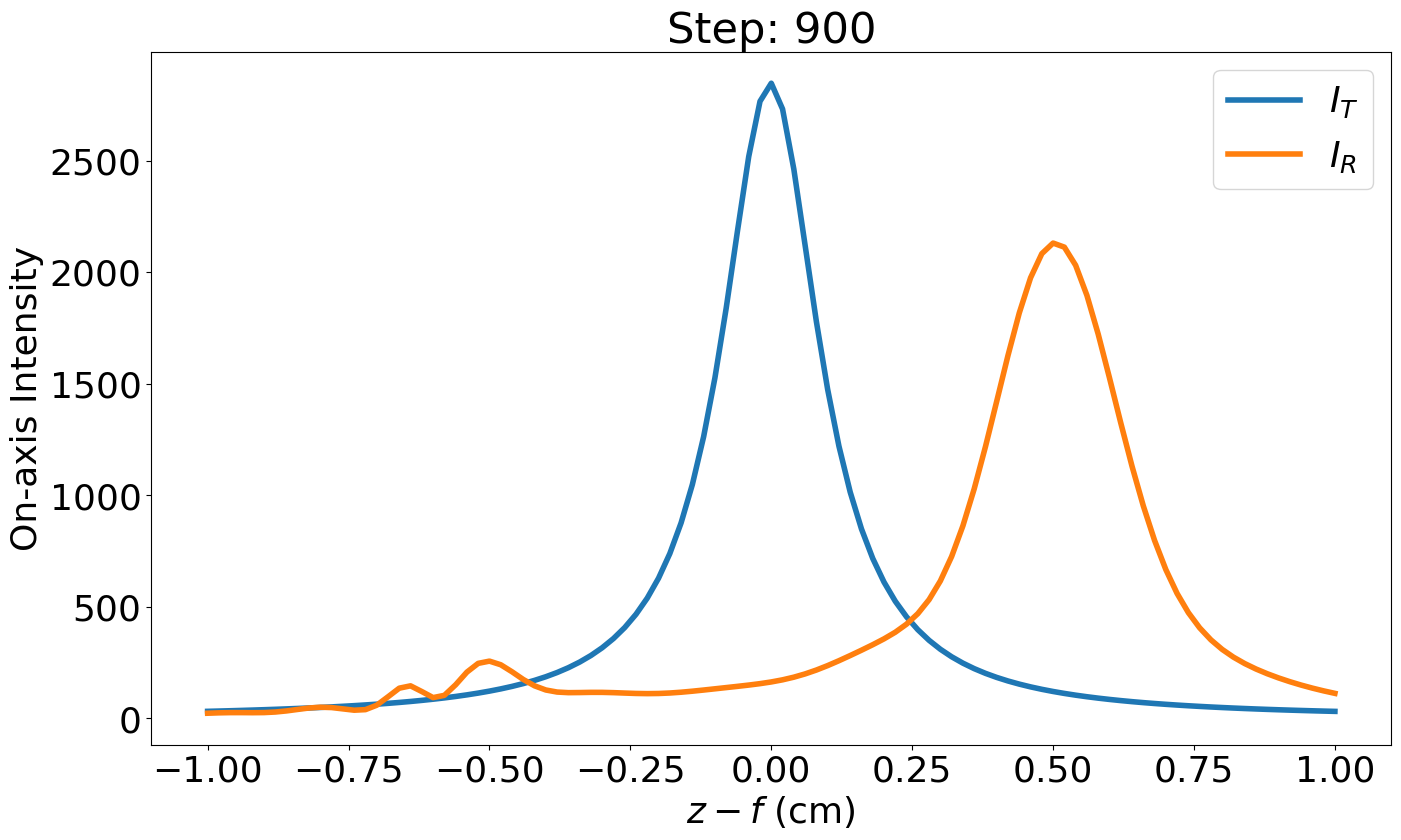

In [36]:
for i, ref in enumerate(I_oa):
    if i%100 == 0:
        plt.plot((zF - f_targ) * 100, np.abs(ftf_t[0])**2, label=r"$I_T$")

        plt.plot((zF - f_targ) * 100, ref, label=r"$I_R$")
        plt.title("Step: %d" % i)
        plt.ylabel("On-axis Intensity")
        plt.xlabel(r"$z-f$ (cm)")
        plt.legend()
        #     plt.show()
        plt.show()